# Robust English SMS Spam Detection Under Controlled Spelling Errors
**Natural Language Processing | Option 1 | First Semester 2026-2027**

Abbas Abdulaziz Al Thunayan (2240004112), Mujtaba Haji Alnuwaysir (2240007941),
and Abdullah Haji Alnuwaysir (2240005501).

**Approved question:** Which method detects misspelled spam messages more reliably?

Compare word TF-IDF + Logistic Regression with frozen `all-MiniLM-L6-v2` + Logistic Regression.
This notebook performs the investigation, saves genuine results, and accepts unfamiliar SMS text.
Run every cell in order using **Jupyter with Python 3.12**. All essential files are in the repository.
The accompanying report explains the findings. Original student examples and contribution evidence
are deliberately left for each student to supply in the editable appendix.

## 1. Setup
Create a virtual environment, install `requirements.txt`, and choose that environment as the Jupyter kernel.
The optional installation cell below is disabled after execution; set `INSTALL_DEPENDENCIES=True` if needed.
The first online run downloads UCI data and the exact pretrained model. The technical archive includes
the dataset and saved encoder for offline inference. CPU execution is used for reproducibility.

The implementation is in `src/project.py`; functions here expose each stage rather than hiding an experiment
inside one opaque cell. No spelling correction, stopword removal, stemming, or corpus-wide classifier fitting is used.

In [1]:
from pathlib import Path
import sys, os, json, importlib.metadata as metadata

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidates if (p / "src" / "project.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or its notebooks folder.")
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "huggingface"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")])

import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from src.project import (SEED, acquire_data, group_and_split, train_tfidf,
    load_encoder, train_minilm, make_variants, evaluate, paired_analysis,
    make_figures, collect_errors, demo_checks, SpamPredictor)
print("Python:", sys.version.split()[0], "| Seed:", SEED)
display(pd.Series({p: metadata.version(p) for p in ["numpy", "pandas", "scikit-learn", "torch", "transformers", "sentence-transformers", "wordfreq"]}, name="Installed version"))

Python: 3.12.10 | Seed: 20261116


numpy                     2.5.3
pandas                    2.3.3
scikit-learn              1.7.2
torch                    2.14.1
transformers             4.44.2
sentence-transformers     5.1.2
wordfreq                  3.1.1
Name: Installed version, dtype: object

## 2. Data
Use the authentic UCI archive and parse **each physical line at its first tab**. This avoids CSV quotation
rules changing the record count. Preserve original text, remove exact duplicate messages, and quarantine any
identical message assigned conflicting labels. The audit reports actual counts and SHA-256 checksums.

For leakage control, group case/whitespace/number/URL/email-normalized templates and connected components
with character 3-5gram TF-IDF cosine similarity at least 0.92. This grouping representation is used only to
identify related examples; neither classifier receives it. No labels select grouping edges. Twenty stratified
group folds give target proportions 70/15/15 (14/3/3 folds). Entire groups stay in one partition; actual sizes
can differ slightly. No sender or campaign metadata is available, so this does not prove all semantic relations
have been eliminated.

In [2]:
data, data_audit = acquire_data(ROOT)
data, split_audit = group_and_split(data, ROOT)
display(pd.Series(data_audit, name="Data audit"))
display(pd.DataFrame(split_audit["counts"]).T)
display(pd.Series({k:v for k,v in split_audit.items() if k != "counts"}, name="Split audit"))
display(data[["row_id","label","text","split"]].head(5))
assert data.groupby("group_id").split.nunique().max() == 1
assert not data.text.duplicated().any()

source                      https://archive.ics.uci.edu/dataset/228/sms+sp...
download_url                https://archive.ics.uci.edu/static/public/228/...
archive_sha256              1587ea43e58e82b14ff1f5425c88e17f8496bfcdb67a58...
raw_sha256                  7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de056...
raw_records                                                              5574
physical_lines                                                           5574
raw_class_counts                                        {'0': 4827, '1': 747}
malformed_records                                                          []
missing_text                                                                0
exact_duplicate_rows                                                      403
conflicting_unique_texts                                                    0
quarantined_rows                                                            0
clean_records                                                   

,total,ham,spam
development,771,700,71
test,781,672,109
train,3619,3146,473


seed                                                                         20261116
target_ratios                       {'train': 0.7, 'development': 0.15, 'test': 0.15}
strategy                            20 stratified group folds; folds 0-13 train, 1...
groups                                                                           5024
near_duplicate_edges_ge_0_92                                                      232
largest_group                                                                      12
exact_text_overlap                                                                  0
group_overlap                                                                       0
near_duplicate_cross_split_edges                                                    0
limitations                         No campaign or sender identifiers exist. Simil...
Name: Split audit, dtype: object

,row_id,label,text,split
0,1,0,"Go until jurong point, crazy.. Available only ...",development
1,2,0,Ok lar... Joking wif u oni...,development
2,3,1,Free entry in 2 a wkly comp to win FA Cup fina...,development
3,4,0,U dun say so early hor... U c already then say...,train
4,5,0,"Nah I don't think he goes to usf, he lives aro...",train


## 3. Method 1
Word TF-IDF retains unigrams or unigrams and bigrams, uses sublinear term frequency and minimum document
frequency 1, lowercases text, and uses scikit-learn's default two-or-more-character word tokenizer.
Fit the vocabulary and inverse document frequencies **only on training text**. Tune Logistic Regression
over `C={0.5,2,8}` and class weights `{None,balanced}` (12 settings). `liblinear`, maximum 2,000 iterations,
and a 0.5 decision threshold are fixed. Select by development macro F1, then spam recall, then fewer false
positives, with stable grid order breaking any remaining tie. Keep the selected training-only model; do not
refit on development examples.

In [3]:
tfidf, tfidf_selection = train_tfidf(data, ROOT)
display(pd.read_csv(ROOT / "results/tfidf_development_grid.csv"))
display(pd.Series(tfidf_selection, name="Selected TF-IDF configuration"))

,ngrams,C,class_weight,n,accuracy,macro_f1,spam_precision,spam_recall,spam_f1,false_positives,false_positive_rate,false_negatives,tn,tp
0,"(1, 1)",0.5,NaN,771,0.962387,0.861534,1.000000,0.591549,0.743363,0,0.000000,29,700,42
1,"(1, 1)",0.5,balanced,771,0.975357,0.931069,0.817073,0.943662,0.875817,15,0.021429,4,685,67
2,"(1, 1)",2.0,NaN,771,0.981842,0.942005,0.967213,0.830986,0.893939,2,0.002857,12,698,59
3,"(1, 1)",2.0,balanced,771,0.976654,0.934315,0.827160,0.943662,0.881579,14,0.020000,4,686,67
4,"(1, 1)",8.0,NaN,771,0.988327,0.964418,0.955882,0.915493,0.935252,3,0.004286,6,697,65
5,"(1, 1)",8.0,balanced,771,0.985733,0.958132,0.905405,0.943662,0.924138,7,0.010000,4,693,67
6,"(1, 2)",0.5,NaN,771,0.942931,0.760275,1.000000,0.380282,0.551020,0,0.000000,44,700,27
7,"(1, 2)",0.5,balanced,771,0.979248,0.940920,0.848101,0.943662,0.893333,12,0.017143,4,688,67
8,"(1, 2)",2.0,NaN,771,0.975357,0.917296,0.981481,0.746479,0.848000,1,0.001429,18,699,53
9,"(1, 2)",2.0,balanced,771,0.981842,0.947681,0.870130,0.943662,0.905405,10,0.014286,4,690,67


chosen_index                                                           10
selected                {'ngrams': '(1, 2)', 'C': 8.0, 'class_weight':...
vocabulary_size                                                     38657
threshold                                                             0.5
refit_on_development                                                False
Name: Selected TF-IDF configuration, dtype: object

## 4. Method 2
Load the authentic SentenceTransformer `sentence-transformers/all-MiniLM-L6-v2`, pin its resolved Hugging
Face revision, set evaluation mode and `requires_grad=False` on every parameter. Produce normalized
384-dimensional sentence embeddings with batch size 64 and the model's default 256-wordpiece truncation.
Only Logistic Regression is trained. Tune `C={0.5,2,8,32}` and weights `{None,balanced}` using the identical
development set and selection rule. The default decision threshold remains 0.5. The encoder was pretrained
externally; corpus-specific TF-IDF statistics and classifier coefficients use training examples only.

In [4]:
encoder, encoder_info = load_encoder(ROOT)
minilm, minilm_selection = train_minilm(data, encoder, ROOT)
display(pd.Series(encoder_info, name="Pretrained encoder provenance"))
display(pd.read_csv(ROOT / "results/minilm_development_grid.csv"))
display(pd.Series(minilm_selection, name="Selected MiniLM configuration"))
assert all(not p.requires_grad for p in encoder.parameters())

model_id                           sentence-transformers/all-MiniLM-L6-v2
revision                         1110a243fdf4706b3f48f1d95db1a4f5529b4d41
embedding_dimension                                                   384
device                                                                cpu
normalize_embeddings                                                 True
max_seq_length                                                        256
frozen                                                               True
source                  https://huggingface.co/sentence-transformers/a...
parameter_count                                                  22713216
weight_file                                             model.safetensors
weights_sha256          1377e9af0ca0b016a9f2aa584d6fc71ab3ea6804fae21e...
Name: Pretrained encoder provenance, dtype: object

,C,class_weight,n,accuracy,macro_f1,spam_precision,spam_recall,spam_f1,false_positives,false_positive_rate,false_negatives,tn,tp
0,0.5,NaN,771,0.976654,0.922215,0.981818,0.760563,0.857143,1,0.001429,17,699,54
1,0.5,balanced,771,0.974060,0.928682,0.800000,0.957746,0.871795,17,0.024286,3,683,68
2,2.0,NaN,771,0.987030,0.959135,0.984127,0.873239,0.925373,1,0.001429,9,699,62
3,2.0,balanced,771,0.983139,0.951710,0.871795,0.957746,0.912752,10,0.014286,3,690,68
4,8.0,NaN,771,0.992218,0.975807,1.000000,0.915493,0.955882,0,0.000000,6,700,65
5,8.0,balanced,771,0.981842,0.947681,0.870130,0.943662,0.905405,10,0.014286,4,690,67
6,32.0,NaN,771,0.990921,0.971961,0.984848,0.915493,0.948905,1,0.001429,6,699,65
7,32.0,balanced,771,0.983139,0.951123,0.881579,0.943662,0.911565,9,0.012857,4,691,67


chosen_index                                                            4
selected                {'C': 8.0, 'class_weight': 'None', 'n': 771, '...
threshold                                                             0.5
refit_on_development                                                False
Name: Selected MiniLM configuration, dtype: object

## 5. Results
Both configurations are now fixed. Open the held-out test partition and generate one-edit variants.
Evaluate **clean**, **deletion**, **transposition**, and a seeded **mixed** condition. Mixed selects deletion
or transposition once per message; it is not an additional edit.

Eligible words contain at least five ASCII letters and have English wordfreq Zipf frequency at least 3.0.
Exclude URLs, emails and tokens containing digits. Delete one internal character or swap two unequal adjacent
internal characters; keep first and last letters unchanged. Reject outputs with Zipf frequency at least 2.5
to reduce real-word substitutions. Select an eligible word uniformly and an allowed edit uniformly using
seed `20261116`, row ID and operation. This conservative heuristic cannot guarantee unchanged semantics.
All transformations, unchanged messages, and edit positions are recorded. No variant trains or tunes a model.

Primary metrics use the **same full test set**, including flagged unchanged messages. Secondary modified-only
metrics use the matching eligible clean cohort, so changes cannot be attributed to a changed denominator.
Spam is positive. False-positive rate is FP / (FP + TN). Macro F1 averages ham and spam F1 equally.

In [5]:
test = data[data.split == "test"].reset_index(drop=True)
variants = make_variants(test, ROOT)
coverage = pd.DataFrame([{ "condition":k, "total":len(v), "modified":int(v.modified.sum()),
    "unchanged":int((~v.modified).sum()), "modified_spam":int(((v.label==1)&v.modified).sum()) }
    for k,v in variants.items()])
display(coverage)
display(variants["mixed"].loc[variants["mixed"].modified,
    ["row_id","label","text","text_variant","operation","original_word","replacement_word"]].head(8))
metrics = evaluate(data, tfidf, encoder, minilm, variants, ROOT)
display(metrics[metrics.cohort == "all"].round(6))
display(metrics[metrics.cohort == "modified_only"].round(6))

,condition,total,modified,unchanged,modified_spam
0,deletion,781,707,74,109
1,transposition,781,708,73,109
2,mixed,781,707,74,109


,row_id,label,text,text_variant,operation,original_word,replacement_word
0,30,0,Ahhh. Work. I vaguely remember that! What does...,Ahhh. Work. I vageuly remember that! What does...,transposition,vaguely,vageuly
1,31,0,"Wait that's still not all that clear, were you...","Wait that's still not all that clear, were you...",transposition,doesn,dosen
2,32,0,Yeah he got in at 2 and was v apologetic. n ha...,Yeah he got in at 2 and was v apologetic. n ha...,deletion,child,chld
3,51,0,What you thinked about me. First time you saw ...,What you thinked about me. Frst time you saw m...,deletion,First,Frst
4,52,0,"A gram usually runs like &lt;#&gt; , a half e...","A gram usually runs like &lt;#&gt; , a half e...",transposition,whole,wohle
5,53,0,K fyi x has a ride early tomorrow morning but ...,K fyi x has a ride early tomorrow morning but ...,deletion,crashing,crahing
6,72,0,Finished class where are you.,Finishd class where are you.,deletion,Finished,Finishd
7,73,0,HI BABE IM AT HOME NOW WANNA DO SOMETHING? XX,HI BABE IM AT HOME NOW WANNA DO SOMETHNIG? XX,transposition,SOMETHING,SOMETHNIG


,model,condition,cohort,n,accuracy,macro_f1,spam_precision,spam_recall,spam_f1,false_positives,false_positive_rate,false_negatives,tn,tp
0,TF-IDF,clean,all,781,0.974392,0.943142,0.978495,0.834862,0.900990,2,0.002976,18,670,91
1,MiniLM,clean,all,781,0.975672,0.946658,0.968750,0.853211,0.907317,3,0.004464,16,669,93
2,TF-IDF,deletion,all,781,0.973111,0.939533,0.988889,0.816514,0.894472,1,0.001488,20,671,89
5,MiniLM,deletion,all,781,0.976953,0.950084,0.959596,0.871560,0.913462,4,0.005952,14,668,95
8,TF-IDF,transposition,all,781,0.974392,0.942658,0.989011,0.825688,0.900000,1,0.001488,19,671,90
11,MiniLM,transposition,all,781,0.976953,0.949674,0.969072,0.862385,0.912621,3,0.004464,15,669,94
14,TF-IDF,mixed,all,781,0.973111,0.939533,0.988889,0.816514,0.894472,1,0.001488,20,671,89
17,MiniLM,mixed,all,781,0.976953,0.950084,0.959596,0.871560,0.913462,4,0.005952,14,668,95


,model,condition,cohort,n,accuracy,macro_f1,spam_precision,spam_recall,spam_f1,false_positives,false_positive_rate,false_negatives,tn,tp
3,TF-IDF,deletion,modified_only,707,0.970297,0.938594,0.988889,0.816514,0.894472,1,0.001672,20,597,89
4,TF-IDF,deletion_clean_counterpart,modified_only,707,0.971711,0.942244,0.978495,0.834862,0.900990,2,0.003344,18,596,91
6,MiniLM,deletion,modified_only,707,0.974540,0.949268,0.959596,0.871560,0.913462,4,0.006689,14,594,95
7,MiniLM,deletion_clean_counterpart,modified_only,707,0.973126,0.945801,0.968750,0.853211,0.907317,3,0.005017,16,595,93
9,TF-IDF,transposition,modified_only,708,0.971751,0.941776,0.989011,0.825688,0.900000,1,0.001669,19,598,90
10,TF-IDF,transposition_clean_counterpart,modified_only,708,0.971751,0.942258,0.978495,0.834862,0.900990,2,0.003339,18,597,91
12,MiniLM,transposition,modified_only,708,0.974576,0.948873,0.969072,0.862385,0.912621,3,0.005008,15,596,94
13,MiniLM,transposition_clean_counterpart,modified_only,708,0.973164,0.945814,0.968750,0.853211,0.907317,3,0.005008,16,596,93
15,TF-IDF,mixed,modified_only,707,0.970297,0.938594,0.988889,0.816514,0.894472,1,0.001672,20,597,89
16,TF-IDF,mixed_clean_counterpart,modified_only,707,0.971711,0.942244,0.978495,0.834862,0.900990,2,0.003344,18,596,91


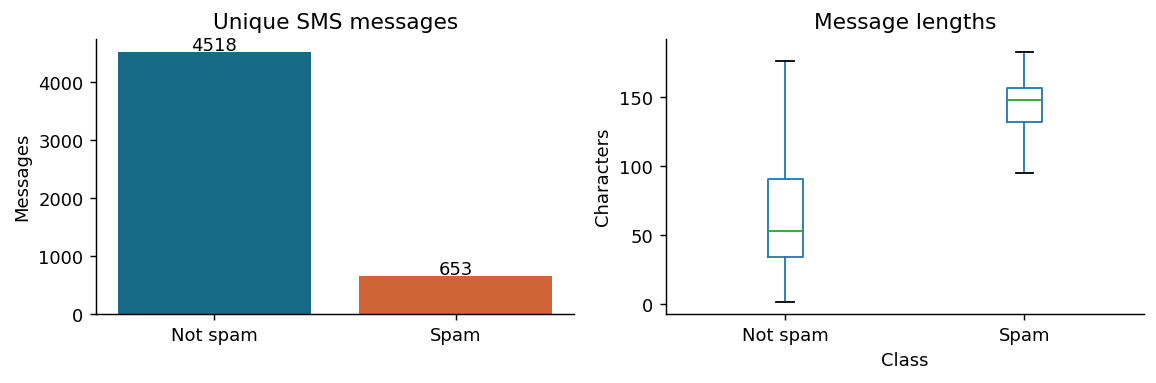

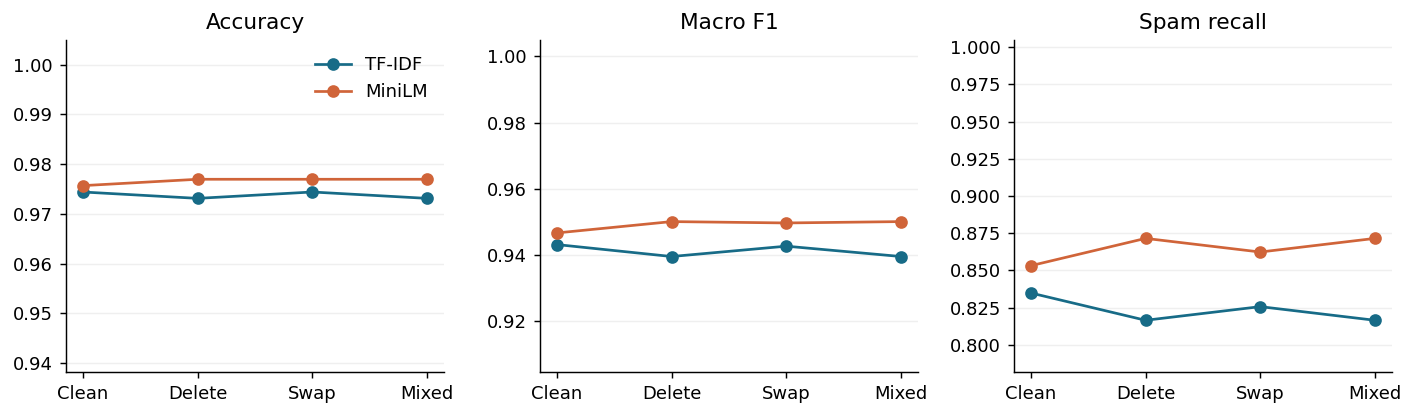

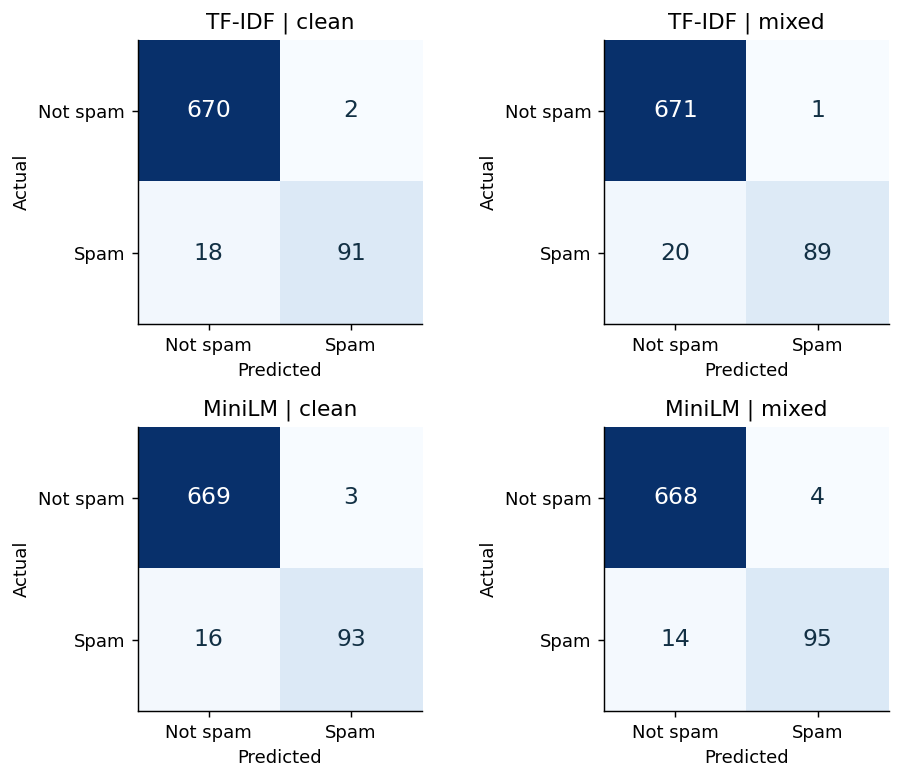

,model,condition,accuracy_change_pp,macro_f1_change_pp,spam_recall_change_pp,false_positives_change
0,TF-IDF,deletion,-0.128,-0.361,-1.835,-1
1,TF-IDF,transposition,0.000,-0.048,-0.917,-1
2,TF-IDF,mixed,-0.128,-0.361,-1.835,-1
3,MiniLM,deletion,0.128,0.343,1.835,1
4,MiniLM,transposition,0.128,0.302,0.917,0
5,MiniLM,mixed,0.128,0.343,1.835,1


In [6]:
make_figures(data, metrics, ROOT)
display(Image(filename=str(ROOT / "results/figures/data_overview.png")))
display(Image(filename=str(ROOT / "results/figures/performance_comparison.png")))
display(Image(filename=str(ROOT / "results/figures/confusion_matrices.png")))
all_metrics = metrics[metrics.cohort == "all"].set_index(["model","condition"])
changes = []
for model in ["TF-IDF","MiniLM"]:
    clean = all_metrics.loc[(model,"clean")]
    for condition in ["deletion","transposition","mixed"]:
        r = all_metrics.loc[(model,condition)]
        changes.append({"model":model,"condition":condition,
            **{m+"_change_pp":100*(r[m]-clean[m]) for m in ["accuracy","macro_f1","spam_recall"]},
            "false_positives_change":int(r.false_positives-clean.false_positives)})
display(pd.DataFrame(changes).round(3))

### Paired evidence and interpretation
The spam analysis compares each pair of model predictions on the same spam messages (modified spam only
for typo conditions). A seeded 5,000-resample paired bootstrap gives percentile intervals for the MiniLM
minus TF-IDF recall difference. The exact McNemar/binomial p-values are exploratory, unadjusted for multiple
conditions, and do not measure universal superiority. Intervals resample messages rather than related groups
and may be optimistic when residual within-campaign dependence remains. This is one group split and one typo
seed, not a multi-dataset benchmark.

In [7]:
paired = paired_analysis(ROOT)
display(paired.round(6))
errors = collect_errors(ROOT)
display(errors.groupby(["model","condition"]).size().unstack(fill_value=0))
analysis = pd.read_csv(ROOT / "results/error_analysis.csv")
display(analysis[["row_id","model","condition","label","prediction","text","text_variant","explanation"]])
display(Markdown((ROOT / "results/conclusions.md").read_text(encoding="utf-8")))

,condition,spam_n,tfidf_only_correct,minilm_only_correct,recall_difference_minilm_minus_tfidf,paired_bootstrap_95_low,paired_bootstrap_95_high,mcnemar_exact_p_exploratory
0,clean,109,1,3,0.018349,-0.018349,0.055046,0.625000
1,deletion,109,1,7,0.055046,0.009174,0.110092,0.070312
2,transposition,109,1,5,0.036697,0.000000,0.082569,0.218750
3,mixed,109,2,8,0.055046,0.000000,0.110092,0.109375


condition,clean,deletion,mixed,transposition
model,,,,
MiniLM,19,18,18,18
TF-IDF,20,21,21,20


,row_id,model,condition,label,prediction,text,text_variant,explanation
0,661,TF-IDF,mixed,1,0,88800 and 89034 are premium phone services cal...,88800 and 89034 are premium phone servcies cal...,Changing services to servcies removes a famili...
1,375,MiniLM,mixed,0,1,I cant keep talking to people if am not sure i...,I cant keep talking to people if am not sure i...,A legitimate discussion of paying and negotiat...
2,1502,TF-IDF,clean,0,1,Host-based IDPS for linux systems.,Host-based IDPS for linux systems.,This short legitimate technical fragment provi...
3,2775,TF-IDF,clean,1,0,How come it takes so little time for a child w...,How come it takes so little time for a child w...,The corpus marks this rhetorical question as s...


### Answer to the approved question

On this held-out group split, **MiniLM detects misspelled spam more reliably by recall**.
For the mixed condition it detects 95 of 109 spam messages (87.16%), compared with
89 of 109 (81.65%) for TF-IDF: an advantage of 5.50 percentage points, or six messages.
Its full-set mixed accuracy is 97.70% and macro F1 is 0.9501, versus 97.31% and 0.9395.
It also has higher recall in deletion-only and transposition-only conditions.

The tradeoff is false positives: MiniLM flags 4 of 672 ham messages in the mixed
condition (0.60%), versus 1 for TF-IDF (0.15%). MiniLM therefore is not superior on every
practical criterion. From clean to mixed, TF-IDF recall decreases by 1.83 points and
MiniLM recall increases by 1.83 points. Small perturbations can move borderline examples
in either direction; the improvement does not mean misspellings inherently help a model.

The mixed paired recall-difference interval is 0.00 to 11.01 points and exploratory
exact McNemar p=0.1094. With only 109 spam examples, these results do not establish
population-wide superiority. Message-level bootstrap intervals may understate uncertainty
from related messages. Report the observed advantage and uncertainty together.

### Scope and limitations

One older English corpus, one group split, one typo seed and one internal edit per message
limit external validity. Only 707/781 mixed messages are modified; all 109 spam messages
are modified. The full-set analysis includes 74 unchanged ham messages, while modified-only
results compare the same eligible cohort before and after editing. The safety lexicon reduces
real-word substitutions but does not guarantee unchanged semantics. Numbers and URLs are protected.
Class proportions differ somewhat between group partitions; the development set contains only
71 spam messages. Neither model uses sender information, and output scores are uncalibrated.
The encoder may truncate unusually long inputs at 256 wordpieces. Grouping reduces related-text
leakage but cannot identify every campaign relationship or rule out overlap in unknown external
pretraining data. Inspect raw messages carefully before treating annotation ambiguity as an error.

A useful next experiment is character n-gram features or training-only typo augmentation,
evaluated using a newly held-out group split and multiple corruption seeds. Do not tune this
improvement on the reported test set. In practice, these classifiers should assist review rather
than automatically delete messages based on an unvalidated threshold.


## 6. Try it
Reload serialized classifiers and reuse the frozen encoder. The function accepts arbitrary unfamiliar text
without retraining. Scores are **uncalibrated outputs**, not guaranteed probabilities of spam. Empty or
whitespace-only input returns a helpful message. The demonstration examples below were prepared by AI for
interface testing; they are not student-authored appendix examples and are excluded from test scores.

In [8]:
predictor = SpamPredictor(ROOT, encoder=encoder)
def predict_sms(message, model="both"):
    return predictor.predict(message, model)

examples = demo_checks(encoder, ROOT)
for kind, result in examples.items():
    print(kind, "->", result)

# Edit this string and rerun this cell. No training occurs.
predict_sms("Please bring your notebook to tomorrow's lab.", model="both")

legitimate -> {'input': "Please bring your notebook to tomorrow's lab.", 'result': {'TF-IDF': {'prediction': 'Not spam', 'uncalibrated_spam_score': 0.16693534539640537}, 'MiniLM': {'prediction': 'Not spam', 'uncalibrated_spam_score': 4.0376313322228955e-05}}}
spam -> {'input': 'Congratulations! You have won a cash prize. Call now to claim your free reward!', 'result': {'TF-IDF': {'prediction': 'Spam', 'uncalibrated_spam_score': 0.9964807440499831}, 'MiniLM': {'prediction': 'Spam', 'uncalibrated_spam_score': 0.984619490921079}}}
misspelled_spam -> {'input': 'Congratulatinos! You have won a cash prize. Call now to claim your free reward!', 'result': {'TF-IDF': {'prediction': 'Spam', 'uncalibrated_spam_score': 0.9976922749910327}, 'MiniLM': {'prediction': 'Spam', 'uncalibrated_spam_score': 0.9822617699942288}}}
ambiguous -> {'input': 'I have a free ticket for you. Call me after class.', 'result': {'TF-IDF': {'prediction': 'Not spam', 'uncalibrated_spam_score': 0.17673933838501116}, 'MiniL

{'TF-IDF': {'prediction': 'Not spam',
  'uncalibrated_spam_score': 0.16693534539640537},
 'MiniLM': {'prediction': 'Not spam',
  'uncalibrated_spam_score': 4.0376313322228955e-05}}

In [9]:
import ipywidgets as widgets
message_box = widgets.Textarea(value="", placeholder="Type an English SMS here", description="SMS:", layout=widgets.Layout(width="95%", height="95px"))
model_choice = widgets.Dropdown(options=["both","TF-IDF","MiniLM"], value="both", description="Model:")
predict_button = widgets.Button(description="Predict SMS", button_style="primary")
prediction_output = widgets.Output()
def show_prediction(_):
    with prediction_output:
        prediction_output.clear_output()
        display(predict_sms(message_box.value, model_choice.value))
predict_button.on_click(show_prediction)
display(widgets.VBox([message_box, model_choice, predict_button, prediction_output]))

## 7. Sources
1. T. A. Almeida, J. M. G. Hidalgo and A. Yamakami, "Contributions to the study of SMS spam filtering: new collection and results," DocEng 2011, pp. 259-262. https://doi.org/10.1145/2034691.2034742
2. T. Almeida and J. Hidalgo, *SMS Spam Collection*, UCI, 2011. https://doi.org/10.24432/C5CC84. Dataset: https://archive.ics.uci.edu/dataset/228/sms+spam+collection (CC BY 4.0).
3. N. Reimers and I. Gurevych, "Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks," EMNLP-IJCNLP 2019, pp. 3982-3992. https://aclanthology.org/D19-1410/
4. Sentence Transformers, *all-MiniLM-L6-v2 model card*. https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2 (Apache 2.0). The resolved revision and weight checksum are recorded in `models/encoder_metadata.json`; packaged-file checksums are in `SHA256SUMS.txt`.
5. Scikit-learn documentation: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction and https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
6. wordfreq project and data attribution: https://github.com/rspeer/wordfreq. A fixed external English lexicon filters eligible typo edits. It is not classifier training data.

**AI assistance disclosure:** ChatGPT/Codex assisted with implementation, experimentation, debugging,
documentation and formatting. Numerical claims come from executed code and stored predictions. Team members
must review and understand the implementation, supply their own six labelled examples and dated contribution
evidence, and complete the postponed presentation. Planned proposal roles are not asserted as completed work.